In [142]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.datasets import make_regression, load_breast_cancer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split

plt.rcParams["figure.figsize"] = (10, 6)

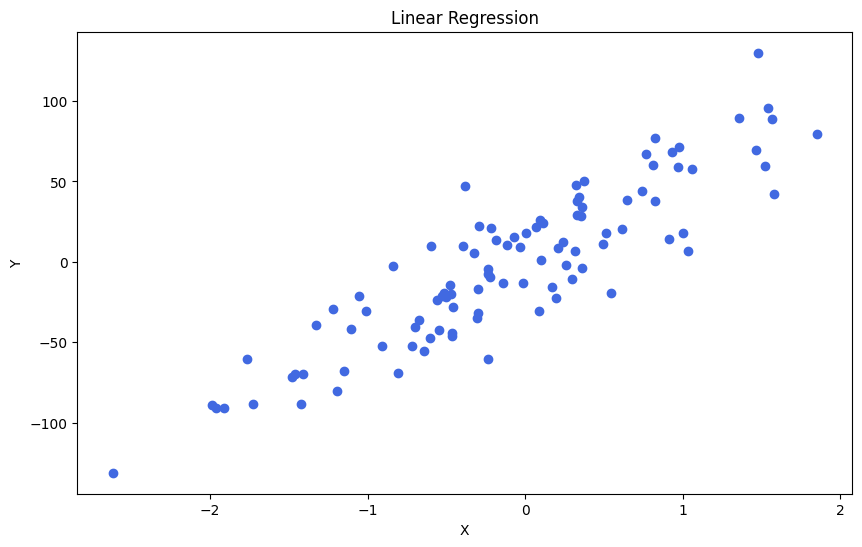

In [20]:
X, y = make_regression(
    n_samples=100,
    n_features=1,
    noise=25,
    random_state=42
)

plt.scatter(X, y, color="royalblue")
plt.title("Linear Regression")
plt.xlabel("X")
plt.ylabel("Y")

plt.show()

In [21]:
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [22]:
print(f"w = {model.coef_[0]}")
print(f"b = {model.intercept_}")

w = 48.481274508320595
b = 2.9127883013174323


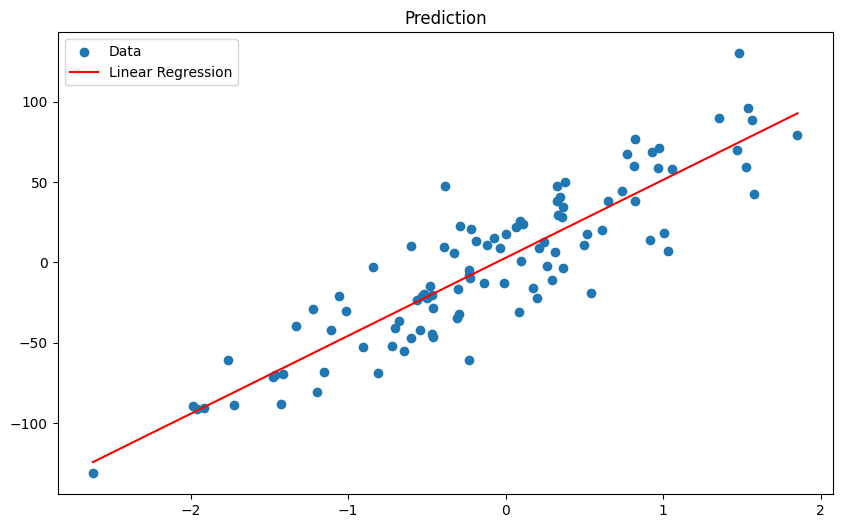

In [23]:
pred = model.predict(X)

idx = np.argsort(X[:, 0])

plt.scatter(X, y, label="Data")

plt.plot(X[idx], pred[idx], label="Linear Regression", color="red")

plt.legend()
plt.title("Prediction")

plt.show()

In [24]:
mse = mean_squared_error(y, pred)

print(f"MSE = {mse}")

MSE = 487.8390651327438


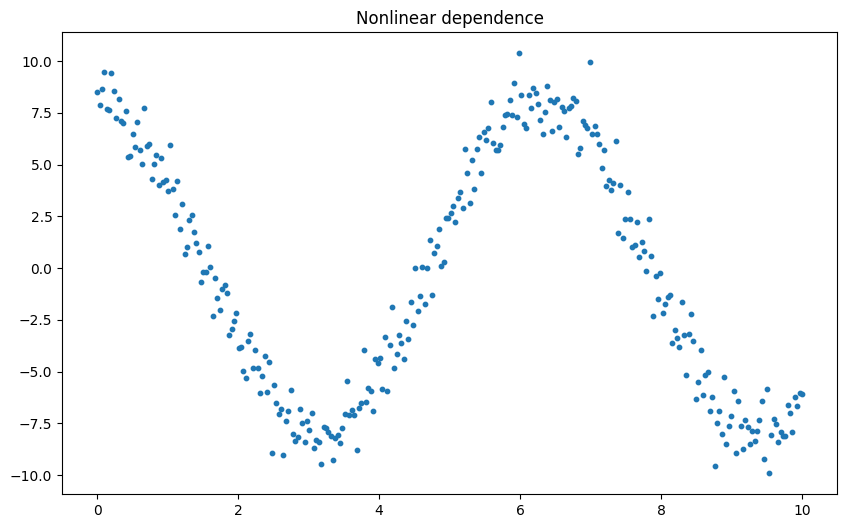

In [55]:
np.random.seed(42)

X = np.linspace(0, 10, 300)
y = 8 * np.cos(X) + 10 * np.random.normal(0, 0.1, len(X))

X = X.reshape(-1, 1)

plt.scatter(X, y, s =10)

plt.title("Nonlinear dependence")
plt.show()

In [56]:
lin_reg = LinearRegression()
lin_reg.fit(X, y)
reg_pred = lin_reg.predict(X)

In [62]:
tree = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)
tree.fit(X, y)
tree_pred = tree.predict(X)

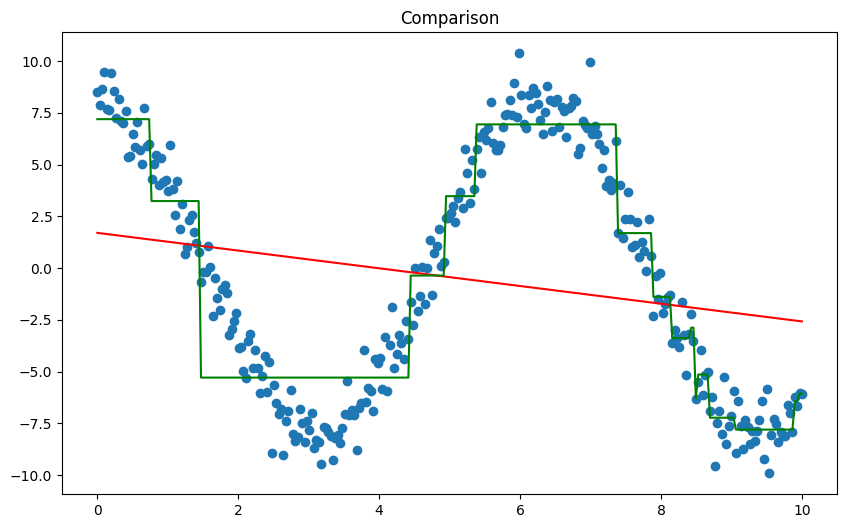

In [63]:
idx = np.argsort(X[:, 0])

plt.scatter(X, y, label="data")

plt.plot(X[idx], reg_pred[idx], color="red", label="Linear Regression")

plt.plot(X[idx], tree_pred[idx], color="green", label="Tree")

plt.title("Comparison")
plt.show()

In [64]:
reg_mse = mean_squared_error(y, reg_pred)
tree_mse = mean_squared_error(y, tree_pred)

print(f"Lin Reg MSE = {reg_mse}")
print(f"Tree MSE = {tree_mse}")

Lin Reg MSE = 33.06149727083235
Tree MSE = 3.007942600200977


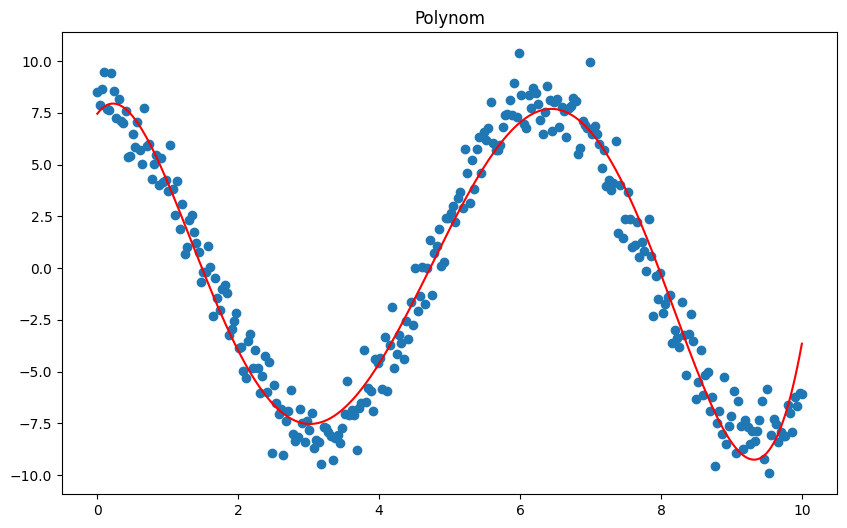

In [69]:
degree = 5
model = Pipeline([
    ('poly', PolynomialFeatures(degree=degree)),
    ('linear', LinearRegression())
])

model.fit(X, y)
poly_pred = model.predict(X)

idx = np.argsort(X[:, 0])

plt.scatter(X, y, label="data")

plt.plot(X[idx], poly_pred[idx], color="red", label="Polynom")

plt.title("Polynom")
plt.show()

In [70]:
poly_mse = mean_squared_error(y, poly_pred)

print(f"Polynom MSE = {poly_mse}")

Polynom MSE = 1.39392868705706


In [82]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df_encoded = pd.get_dummies(df, columns=['Sex'], drop_first=True)
df_encoded.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_male
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,S,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,C,False
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,S,False
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,S,True


In [151]:
X = df_encoded[['Pclass', 'Sex_male', 'Age',  'Survived', 'Parch']]
y = np.log(df_encoded['Fare'] + 1) 

mask = X.notna().all(axis=1)
X=X[mask]
y=y[mask]

X_train, X_test, y_train,  y_test = train_test_split(X, y, random_state=42, test_size=0.2)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)
surv_pred = model.predict(X_test_scaled)

print(f"MSE: {mean_squared_error(y_test, surv_pred):.3f}")
print(f"R²: {r2_score(y_test, surv_pred):.3f}")

#Can't apply linear regression to this dataset :(

MSE: 0.422
R²: 0.490
